# VC · Práctica 5 — 03. Transfer Learning en PyTorch: ResNet-18 vs. EfficientNet-B0 (FER-2013)

Entrenamiento en dos fases (*warm-up* de la cabeza + *fine-tuning* completo) y comparativa directa entre **ResNet-18** y **EfficientNet-B0** sobre la misma partición estratificada (`SEED = 42`) usando `fer_lib/`.

## 1. Configuración, semilla e hiperparámetros

In [1]:
import sys
from pathlib import Path

P5_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "fer_lib").is_dir())
if str(P5_ROOT) not in sys.path:
    sys.path.insert(0, str(P5_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import classification_report, f1_score

from fer_lib.config import MODELS_DIR, SEED, TL_IMG_SIZE, TRAIN_DIR, VAL_SIZE, save_json
from fer_lib.data import compute_smoothed_class_weights, load_split, make_loader, split_train_val
from fer_lib.evaluation import measure_probs, plot_confusion
from fer_lib.models import TransferFER, load_checkpoint
from fer_lib.training import fit_transfer_two_phase, set_seed

set_seed(SEED, warn_only=True)

AUG_ROTATION_DEG = 10.8
AUG_ZOOM = 0.10
BATCH = 64
WARMUP_EPOCHS = 5
FINETUNE_EPOCHS = 35
WARMUP_LR = 1e-3
FINETUNE_LR = 3e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.10
ES_PATIENCE = 10

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert TRAIN_DIR.is_dir(), f"No encuentro train/ en {TRAIN_DIR.parent}"
print(
    f"Training seed: {SEED} | PyTorch {torch.__version__} | device: {device}"
    + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")
)

Training seed: 42 | PyTorch 2.15.0+cu132 | device: cuda (NVIDIA GeForce RTX 3060 Ti)


## 2. Carga de datos y partición estratificada (80/20)

In [2]:
X_full, y_full, CLASS_NAMES = load_split(TRAIN_DIR)
N_CLASSES = len(CLASS_NAMES)
X_tr, X_val, y_tr, y_val = split_train_val(X_full, y_full, val_size=VAL_SIZE, seed=SEED)
cw, cw_tensor = compute_smoothed_class_weights(y_tr, N_CLASSES, power=0.5)

print(f"train: {len(y_tr)} | val: {len(y_val)}")
val_loader = make_loader(X_val, y_val, batch_size=256, shuffle=False, seed=SEED, pin_memory=(device.type == "cuda"))

train/angry:   0%|          | 0/3995 [00:00<?, ?it/s]

train/disgusted:   0%|          | 0/436 [00:00<?, ?it/s]

train/fearful:   0%|          | 0/4097 [00:00<?, ?it/s]

train/happy:   0%|          | 0/7215 [00:00<?, ?it/s]

train/neutral:   0%|          | 0/4965 [00:00<?, ?it/s]

train/sad:   0%|          | 0/4830 [00:00<?, ?it/s]

train/surprised:   0%|          | 0/3171 [00:00<?, ?it/s]

train: 22967 | val: 5742


## 3. Entrenamiento de ResNet-18 y EfficientNet-B0

In [3]:
resultados_tl = {}
criterion = nn.CrossEntropyLoss(weight=cw_tensor.to(device), label_smoothing=LABEL_SMOOTHING)

for bname in ["resnet18", "efficientnet_b0"]:
    set_seed(SEED, warn_only=True)
    tr_loader = make_loader(X_tr, y_tr, batch_size=BATCH, shuffle=True, seed=SEED, pin_memory=(device.type == "cuda"))
    net = TransferFER(
        backbone_name=bname,
        n_classes=N_CLASSES,
        tl_img_size=TL_IMG_SIZE,
        aug_rotation_deg=AUG_ROTATION_DEG,
        aug_zoom=AUG_ZOOM,
        head_dropout=0.30,
        pretrained=True,
    ).to(device)
    n_params = sum(p.numel() for p in net.parameters())
    print(f"\n==================== {bname.upper()} ({n_params:,} params) ====================")
    hist, best_ep, tr_min = fit_transfer_two_phase(
        net,
        tr_loader,
        val_loader,
        criterion,
        device,
        warmup_epochs=WARMUP_EPOCHS,
        finetune_epochs=FINETUNE_EPOCHS,
        warmup_lr=WARMUP_LR,
        finetune_lr=FINETUNE_LR,
        weight_decay=WEIGHT_DECAY,
        es_patience=ES_PATIENCE,
    )
    resultados_tl[bname] = {
        "model": net,
        "history": hist,
        "best_ep": best_ep,
        "train_minutes": tr_min,
        "params": n_params,
    }


==================== RESNET18 (11,180,103 params) ====================
[Warmup 01/5] loss: 1.9724 - acc: 0.2834 | val_loss: 1.8726 - val_acc: 0.3497
[Warmup 02/5] loss: 1.8999 - acc: 0.3221 | val_loss: 1.8416 - val_acc: 0.3765
[Warmup 03/5] loss: 1.8781 - acc: 0.3341 | val_loss: 1.8744 - val_acc: 0.3690
[Warmup 04/5] loss: 1.8799 - acc: 0.3328 | val_loss: 1.8850 - val_acc: 0.3473
[Warmup 05/5] loss: 1.8785 - acc: 0.3310 | val_loss: 1.9067 - val_acc: 0.3502
[FT 01/35] 12.5s - loss: 1.5951 - acc: 0.5013 | val_loss: 1.4735 - val_acc: 0.5472 - lr: 0.000300
[FT 02/35] 12.6s - loss: 1.4393 - acc: 0.5757 | val_loss: 1.4014 - val_acc: 0.5982 - lr: 0.000299
[FT 03/35] 12.8s - loss: 1.3773 - acc: 0.6077 | val_loss: 1.4052 - val_acc: 0.5942 - lr: 0.000298
[FT 04/35] 12.7s - loss: 1.3488 - acc: 0.6252 | val_loss: 1.3259 - val_acc: 0.6388 - lr: 0.000295
[FT 05/35] 12.8s - loss: 1.3091 - acc: 0.6411 | val_loss: 1.3753 - val_acc: 0.6148 - lr: 0.000290
[FT 06/35] 13.1s - loss: 1.2824 - acc: 0.6537 | 

## 4. Curvas de entrenamiento, evaluación en validación y matrices de confusión


=== RESNET18 (con TTA) -> accuracy=0.6877 | F1-macro=0.6693 ===
              precision    recall  f1-score   support

       angry       0.59      0.60      0.60       799
   disgusted       0.64      0.68      0.66        87
     fearful       0.58      0.55      0.56       820
       happy       0.84      0.89      0.87      1443
     neutral       0.63      0.65      0.64       993
         sad       0.60      0.55      0.57       966
   surprised       0.79      0.78      0.78       634

    accuracy                           0.69      5742
   macro avg       0.67      0.67      0.67      5742
weighted avg       0.68      0.69      0.69      5742


=== EFFICIENTNET_B0 (con TTA) -> accuracy=0.6829 | F1-macro=0.6624 ===
              precision    recall  f1-score   support

       angry       0.61      0.58      0.59       799
   disgusted       0.56      0.71      0.63        87
     fearful       0.54      0.59      0.56       820
       happy       0.87      0.88      0.87      

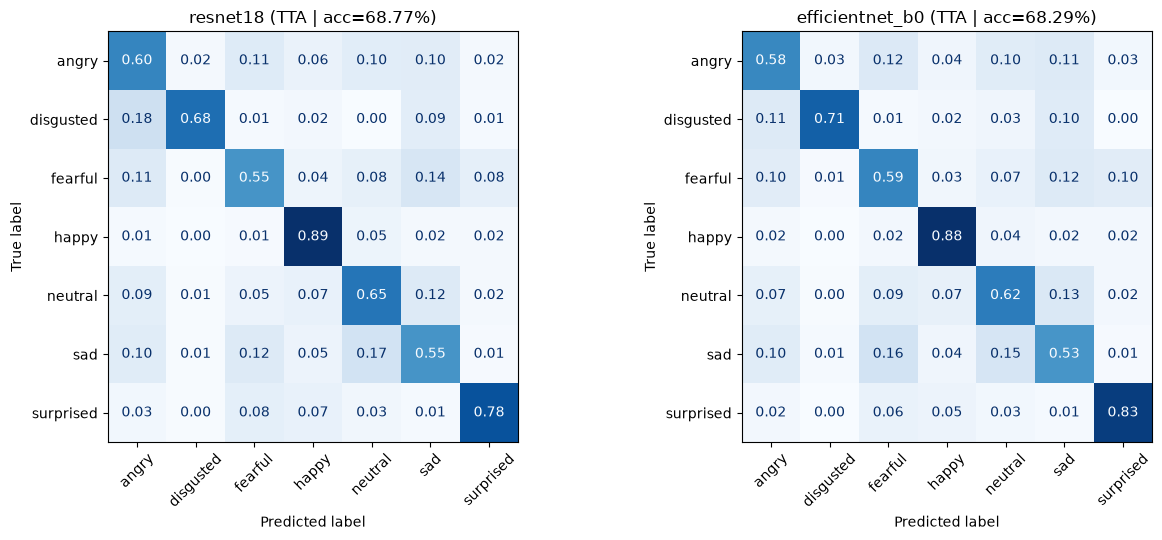

,modelo,params_M,train_min,mejor_epoca,val_acc_sin_tta_pct,val_f1_sin_tta_pct,val_acc_con_tta_pct,val_f1_con_tta_pct,ms_por_img_tta
0,resnet18,11.18,5.8,20,68.18,66.41,68.77,66.93,0.277
1,efficientnet_b0,4.02,7.5,22,67.97,66.01,68.29,66.24,0.450


In [4]:
filas_comparativa = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, (bname, info) in zip(axes, resultados_tl.items()):
    net = info["model"]
    p_no_tta, _ = measure_probs(net, X_val, device=device, use_tta=False)
    p_tta, ms_tta = measure_probs(net, X_val, device=device, use_tta=True)

    y_pred_no_tta = p_no_tta.argmax(1)
    y_pred_tta = p_tta.argmax(1)

    acc_no_tta = float(np.mean(y_pred_no_tta == y_val))
    f1_no_tta = float(f1_score(y_val, y_pred_no_tta, average="macro"))
    acc_tta = float(np.mean(y_pred_tta == y_val))
    f1_tta = float(f1_score(y_val, y_pred_tta, average="macro"))

    info.update(
        val_acc_no_tta=acc_no_tta,
        val_f1_no_tta=f1_no_tta,
        val_acc_tta=acc_tta,
        val_f1_tta=f1_tta,
        ms_img_tta=ms_tta,
    )
    filas_comparativa.append({
        "modelo": bname,
        "params_M": round(info["params"] / 1e6, 2),
        "train_min": round(info["train_minutes"], 1),
        "mejor_epoca": info["best_ep"] + 1,
        "val_acc_sin_tta_pct": round(acc_no_tta * 100, 2),
        "val_f1_sin_tta_pct": round(f1_no_tta * 100, 2),
        "val_acc_con_tta_pct": round(acc_tta * 100, 2),
        "val_f1_con_tta_pct": round(f1_tta * 100, 2),
        "ms_por_img_tta": round(ms_tta, 3),
    })

    print(f"\n=== {bname.upper()} (con TTA) -> accuracy={acc_tta:.4f} | F1-macro={f1_tta:.4f} ===")
    print(classification_report(y_val, y_pred_tta, target_names=CLASS_NAMES, zero_division=0))
    plot_confusion(y_val, y_pred_tta, CLASS_NAMES, title=f"{bname} (TTA | acc={acc_tta:.2%})", ax=ax)

plt.tight_layout()
plt.show()

df_comp = pd.DataFrame(filas_comparativa)
display(df_comp)

### Análisis: Transfer Learning (ResNet-18 vs. EfficientNet-B0)
Se empleó una estrategia de entrenamiento en dos fases sobre entradas reescaladas bilinealmente a $112\times 112$ píxeles y normalizadas con estadísticas de ImageNet:
1. **Fase de *warm-up* (5 épocas, *backbone* congelado, $\text{lr} = 10^{-3}$):** adapta los pesos aleatorios de la cabeza clasificadora sin degradar las representaciones preentrenadas.
2. **Fase de *fine-tuning* completo (hasta 35 épocas, $\text{lr} = 3\cdot 10^{-4}$ con *CosineAnnealingLR*):** ajusta los filtros convolucionales al dominio facial en escala de grises.

En validación con TTA, **ResNet-18** ($11.18\text{ M}$ de parámetros) alcanza **68.77 % de Accuracy y 66.93 % de F1-macro** en $5.8\text{ min}$ ($0.277\text{ ms/img}$), superando ligeramente a **EfficientNet-B0** ($4.02\text{ M}$ de parámetros, **68.29 % Accuracy / 66.24 % F1-macro**, $7.5\text{ min}$, $0.450\text{ ms/img}$). Aunque EfficientNet-B0 es más compacto en número de parámetros, sus convoluciones separables en profundidad resultan más lentas en GPU para lotes pequeños y muestran una convergencia ligeramente inferior en baja resolución facial.


## 5. Comparativa visual directa y guardado de ambos modelos

In [5]:
for bname, info in resultados_tl.items():
    mdir = MODELS_DIR / f"v1_TL_{bname}"
    mdir.mkdir(parents=True, exist_ok=True)
    mname = f"{bname}_fer_torch_seed{SEED}"
    mpath = mdir / f"{mname}.pt"

    arch_cfg = {
        "backbone_name": bname,
        "n_classes": N_CLASSES,
        "tl_img_size": TL_IMG_SIZE,
        "aug_rotation_deg": AUG_ROTATION_DEG,
        "aug_zoom": AUG_ZOOM,
        "head_dropout": 0.30,
        "pretrained": False,
    }
    torch.save(
        {"model_state_dict": info["model"].state_dict(), "class_names": CLASS_NAMES, "arch": arch_cfg},
        mpath,
    )
    save_json(CLASS_NAMES, mdir / "class_names.json")
    pd.DataFrame(info["history"]).to_csv(mdir / f"{mname}_history.csv", index=False)

    cfg = {
        "framework": "pytorch",
        "backbone": bname,
        "seed": SEED,
        "tl_img_size": TL_IMG_SIZE,
        "warmup_epochs": WARMUP_EPOCHS,
        "finetune_epochs": FINETUNE_EPOCHS,
        "epochs_run": len(info["history"]["loss"]),
        "best_epoch": info["best_ep"] + 1,
        "val_acc_no_tta": info["val_acc_no_tta"],
        "val_f1_no_tta": info["val_f1_no_tta"],
        "val_acc_tta": info["val_acc_tta"],
        "val_f1_tta": info["val_f1_tta"],
        "train_minutes": round(info["train_minutes"], 1),
    }
    save_json(cfg, mdir / f"{mname}_config.json")

    reloaded, _, _ = load_checkpoint(mpath, device=device)
    p_orig, _ = measure_probs(info["model"], X_val[:64], device=device, use_tta=True, warmup_n=0)
    p_rel, _ = measure_probs(reloaded, X_val[:64], device=device, use_tta=True, warmup_n=0)
    same = np.allclose(p_rel, p_orig, atol=1e-5)
    print(f"Guardado {mpath} | recarga OK: {same}")

Guardado /home/cris/Proyectos/computer-vision/P5/outputs_p5/models/v1_TL_resnet18/resnet18_fer_torch_seed42.pt | recarga OK: True
Guardado /home/cris/Proyectos/computer-vision/P5/outputs_p5/models/v1_TL_efficientnet_b0/efficientnet_b0_fer_torch_seed42.pt | recarga OK: True
